# Point-In-Time Stability: A Ladder Of Feature Sets

This notebook measures the cost of anonymisation on a ladder of feature sets that separates the predictors that are exactly point-in-time from the predictors that carry information written after the prediction time. Every rung of the ladder is evaluated with the same repeated customer-grouped splits, the same three models and the same release comparison as in the two model stability audits.

> **Hypothesis test: anonymisation cost (classification).** The leakage audit (`01_leakage_audit.ipynb`) showed that only the 12 documented-record predictors are filtered by time, and that the other families (property context, customer attributes, customer profile, video and AI) are not. The three feature sets of the earlier audits jump from 12 to 42 to 55 predictors, so they cannot show where the effect of the anonymisation enters. This notebook adds the rungs in between and a version of the video family that uses only videos created on or before the prediction time.

## Design

- **Splits.** The same as in the stability audits. For each of the 50 seeds (1 to 51, without 42) the table is partitioned by two successive grouped shuffle splits by `Customer_ID` (70% train, then the remainder halved into validation and test), using the source customer labels, and the same partitions are applied to both releases through `Property_ID`. The validation partition is not used.
- **Models.** The Random Forest, the Logistic Regression and the CatBoost model of the stability audits, with the same fixed settings, no search, no tuning and no selection. The preprocessing is the one of the modelling notebooks and is fitted on the training partition only.
- **Feature ladder.** Six rungs, each of which adds one block of predictors to the previous one. The rungs A, D and E are the `pure_record`, `no_ai` and `full` feature sets of the earlier audits, and the rungs B, C and D' are new. They are defined in the next section.
- **Why every rung is refitted.** The comparisons of this notebook are paired within each split (for example rung B minus rung A on the same partition), and the stability audits did not save the scores of the single splits. All rungs are therefore refitted, and the rungs A, D and E are checked against the saved single-split results of the modelling notebooks before the repetitions start.
- **What is reported.** Mean, standard deviation and the 2.5th and 97.5th percentiles over the splits, in the same form as in the audits. The values are descriptive. The splits are drawn from the same 431 states and overlap, so the spread is not the sampling variability of a new set of customers, and no significance statement is made.
- **Run time.** There are 1,800 fits in total (6 rungs, 3 models, 2 releases and 50 splits). The Random Forest and the Logistic Regression are fast and CatBoost is the slowest, so the number of splits of each model can be lowered in the first code cell to shorten the run. Each model is run in its own cell, so a model can be skipped without affecting the others.
- **Where the results are kept.** Every table is printed in the output of the cell that computes it and no result files are written.

## Workflow

The figure shows how the notebook works. The inputs are the model state tables of the two releases and the video table. The feature ladder adds one block of predictors per rung. For each of the 50 seeds the states are split by customer and every rung is fitted for both releases and all three models. The printed tables then give the spread of each rung, the effect of the anonymisation on each rung and the effect of each added block.

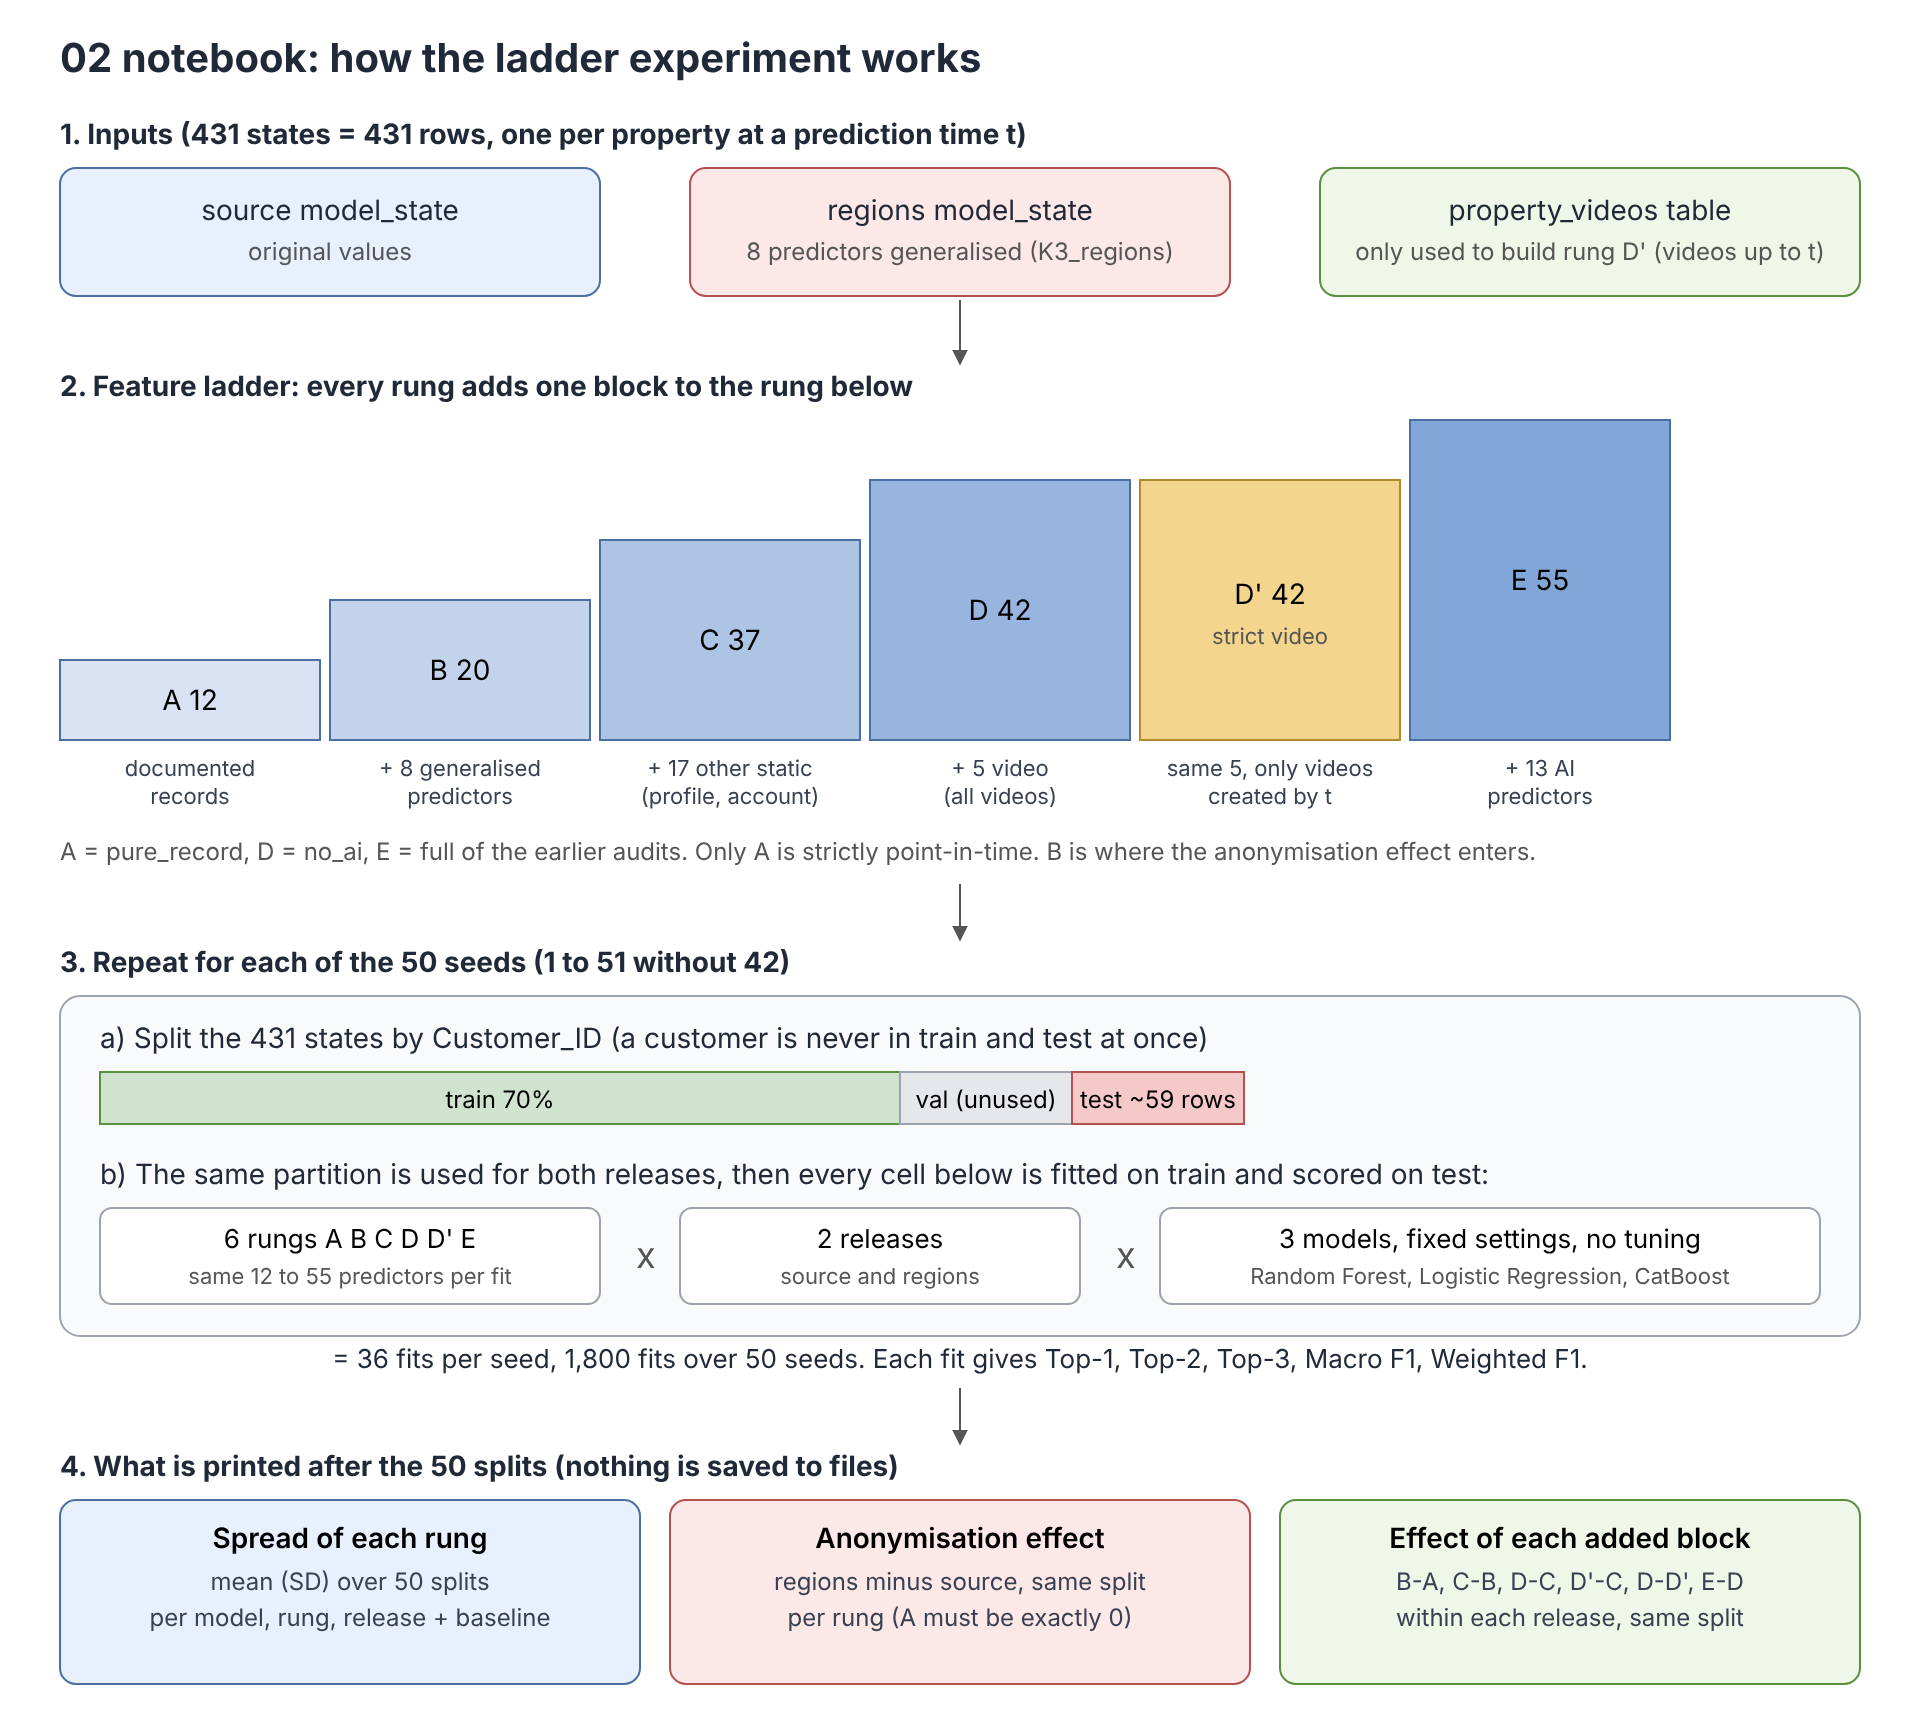

## Setup

The notebook reads the model state tables of the two releases and the video table of the workbook. The video table is needed only to rebuild the video predictors from videos created on or before the prediction time.

In [1]:
# -------------------------------------------------------------------
# Setup
# -------------------------------------------------------------------
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
from catboost import CatBoostClassifier
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score
from sklearn.model_selection import GroupShuffleSplit
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

warnings.filterwarnings("ignore")

pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 40)

DATA_DIR = Path("../../../data/processed/hypothesis_testing")
WORKBOOK_PATH = Path("../../../data/raw/Household_Insurance_Synthetic_Dataset_v2_K3_regions.xlsx")

SEEDS = [seed for seed in range(1, 52) if seed != 42]
CHECK_SEED = 42

# Number of splits used by each model. Lower the value of the slowest model (CatBoost) to shorten the run.
N_SPLITS = {"random_forest": 50, "logistic": 50, "catboost": 50}

for path in [DATA_DIR / "source_dataset" / "model_state.csv", DATA_DIR / "regions_anonymised" / "model_state.csv", WORKBOOK_PATH]:
    if not path.exists():
        raise FileNotFoundError(f"File not found: {path}")

## Data

Both modelling tables have the same rows in the same order. The check below confirms that the keys, timestamps and targets are identical in the two releases, so the same row indices can be used for both.

In [2]:
source = pd.read_csv(DATA_DIR / "source_dataset" / "model_state.csv", parse_dates=["Prediction_Time"])
regions = pd.read_csv(DATA_DIR / "regions_anonymised" / "model_state.csv", parse_dates=["Prediction_Time"])

for column in ["Property_ID", "Prediction_Time", "Next_Category"]:
    assert (source[column].values == regions[column].values).all(), column

videos = pd.read_excel(WORKBOOK_PATH, sheet_name="property_videos")
videos["Created_At"] = pd.to_datetime(videos["Created_At"])

print("DATA LOADED")
print("-" * 60)
print(f"Rows:       {len(source):,}")
print(f"Properties: {source['Property_ID'].nunique():,}")
print(f"Customers:  {source['Customer_ID'].nunique():,}")
print(f"Videos:     {len(videos):,}")

DATA LOADED
------------------------------------------------------------
Rows:       431
Properties: 234
Customers:  198
Videos:     219


## Video Predictors Restricted To Videos Up To The Prediction Time

The five video predictors of the modelling tables are built from every video of the property, whatever its creation time. The function below rebuilds the same five predictors from the videos whose Created_At is not later than Prediction_Time. Without a time restriction it must reproduce the existing columns exactly, which confirms that the definitions are the same, and with the restriction it gives the point-in-time version used by the rung D'. A state that has no video created by its prediction time keeps its row and receives the value 0 in all five predictors, including the mean duration, which is set to 0 instead of being divided by zero. This is the same coding as for the states that never have a video, so the restriction changes values but never removes rows, and it changes the states whose videos were all created after the prediction time from non-zero to zero.

In [3]:
# -------------------------------------------------------------------
# Video Predictors With And Without A Time Restriction
# -------------------------------------------------------------------
VIDEO_FEATURES = [
    "video_count",
    "total_video_duration_seconds",
    "mean_video_duration_seconds",
    "total_rooms_covered",
    "total_items_detected",
]


def video_features(frame, up_to_prediction_time):
    pairs = frame[["Property_ID", "Prediction_Time"]].reset_index().merge(videos, on="Property_ID", how="left")
    pairs = pairs[pairs["Video_ID"].notna()]
    if up_to_prediction_time:
        pairs = pairs[pairs["Created_At"] <= pairs["Prediction_Time"]]

    totals = pairs.groupby("index").agg(
        video_count=("Video_ID", "count"),
        total_video_duration_seconds=("Duration_Seconds", "sum"),
        total_rooms_covered=("Rooms_Covered", "sum"),
        total_items_detected=("Items_Detected", "sum"),
    )
    totals = totals.reindex(frame.index).fillna(0.0)
    totals["mean_video_duration_seconds"] = np.where(
        totals["video_count"] > 0, totals["total_video_duration_seconds"] / totals["video_count"].replace(0, np.nan), 0.0
    )
    return totals[VIDEO_FEATURES]


unrestricted = video_features(source, up_to_prediction_time=False)
for column in VIDEO_FEATURES:
    assert np.allclose(unrestricted[column], source[column]), column
print("Rebuilt from all videos, the five video predictors equal the existing columns in all rows.")

restricted = video_features(source, up_to_prediction_time=True)
has_video = source["video_count"] > 0
print(f"\nStates with a video:                         {int(has_video.sum())}")
print(f"States with a video created by t (restricted): {int((restricted['video_count'] > 0).sum())}")
print(f"States that lose every video:                  {int((has_video & (restricted['video_count'] == 0)).sum())}")
print(f"States without any video (zero in both versions): {int((~has_video).sum())}")
print(f"Rows with at least one value that differs between the two versions: {int((restricted[VIDEO_FEATURES].values != source[VIDEO_FEATURES].values).any(axis=1).sum())} of {len(source)}")
print(f"Rows kept: {len(restricted)} of {len(source)}")

# The restricted columns are added to the modelling tables of both releases under new names.
STRICT_VIDEO_FEATURES = [f"{column}_by_t" for column in VIDEO_FEATURES]
for frame in (source, regions):
    for column, new_column in zip(VIDEO_FEATURES, STRICT_VIDEO_FEATURES):
        frame[new_column] = restricted[column].values

RELEASES = {"source": source, "regions": regions}

Rebuilt from all videos, the five video predictors equal the existing columns in all rows.

States with a video:                         94
States with a video created by t (restricted): 14
States that lose every video:                  80
States without any video (zero in both versions): 337
Rows with at least one value that differs between the two versions: 80 of 431
Rows kept: 431 of 431


## The Feature Ladder

The ladder starts with the 12 documented-record predictors, which are the only ones that are point-in-time by construction and that the anonymisation does not change. The rung B adds the 8 predictors that the anonymisation generalises, so that the step from A to B is the only step in which the source release and the anonymised release differ in what they offer to the model. The rung C adds the remaining static predictors of the property, the customer account and the customer profile, which are not changed by the anonymisation but are not filtered by time either. The rungs D and D' add the video family, without and with the time restriction, and the rung E adds the 13 AI predictors.

| Rung | Predictors | Count | Corresponds to |
|---|---|---|---|
| A | documented records | 12 | `pure_record` of the earlier audits |
| B | A and the 8 generalised predictors | 20 | new |
| C | B and the other static predictors | 37 | new |
| D | C and the video predictors of the modelling table | 42 | `no_ai` of the earlier audits |
| D' | C and the video predictors restricted to videos up to t | 42 | new |
| E | D and the AI predictors | 55 | `full` of the earlier audits |

In [4]:
# -------------------------------------------------------------------
# Feature Ladder
# -------------------------------------------------------------------
IDENTIFIERS = ["Property_ID", "Customer_ID", "Prediction_Time", "Next_Category_ID", "Next_Category"]

original_columns = [column for column in pd.read_csv(DATA_DIR / "source_dataset" / "model_state.csv", nrows=1).columns]
ALL_FEATURES = [column for column in original_columns if column not in IDENTIFIERS]

RECORD_FEATURES = [
    "documented_asset_count",
    "documented_category_count",
    "documented_value_total",
    "documented_replacement_cost_total",
    "mean_evidence_rating",
] + [f"documented_count_CAT-00{number}" for number in range(1, 8)]

GENERALISED_FEATURES = [
    "Age_Band", "Gender", "State", "Occupation",
    "Property_Type", "Number_Of_Bedrooms", "Number_Of_Occupants", "Property_Valuation_AUD",
]

OTHER_STATIC_FEATURES = [
    "Occupancy_Type", "Is_Home_Insured", "Insurance_Coverage_Type", "Is_Primary",
    "Membership_Level", "Account_Status",
    "Financial_Literacy_Band", "Insurance_Confidence_1_5", "Engagement_Tier", "Preferred_Channel",
    "Preferred_Explanation_Style", "Notification_Opt_In", "Household_Type", "Income_Band",
    "Tenure_Months", "Prior_Claim_Experience", "Underinsurance_Awareness",
]

AI_FEATURES = [column for column in ALL_FEATURES if column.startswith("ai_")]

def in_table_order(columns):
    # The columns keep the order of the modelling table, because the order can change the forest slightly.
    return [column for column in ALL_FEATURES if column in set(columns)]


BLOCKS = {
    "A": RECORD_FEATURES,
    "B": GENERALISED_FEATURES,
    "C": OTHER_STATIC_FEATURES,
    "D": VIDEO_FEATURES,
    "E": AI_FEATURES,
}

FEATURE_SETS = {
    "A": in_table_order(BLOCKS["A"]),
    "B": in_table_order(BLOCKS["A"] + BLOCKS["B"]),
    "C": in_table_order(BLOCKS["A"] + BLOCKS["B"] + BLOCKS["C"]),
    "D": in_table_order(BLOCKS["A"] + BLOCKS["B"] + BLOCKS["C"] + BLOCKS["D"]),
    "E": in_table_order(BLOCKS["A"] + BLOCKS["B"] + BLOCKS["C"] + BLOCKS["D"] + BLOCKS["E"]),
}
# The rung D' is the rung D with every video predictor replaced by its restricted version in the same position.
FEATURE_SETS["D'"] = [dict(zip(VIDEO_FEATURES, STRICT_VIDEO_FEATURES)).get(column, column) for column in FEATURE_SETS["D"]]
FEATURE_SETS = {rung: FEATURE_SETS[rung] for rung in ["A", "B", "C", "D", "D'", "E"]}

# The ladder must contain every predictor of the earlier audits and nothing else.
assert FEATURE_SETS["E"] == ALL_FEATURES and len(FEATURE_SETS["E"]) == 55
assert FEATURE_SETS["D"] == [c for c in ALL_FEATURES if not c.startswith("ai_")] and len(FEATURE_SETS["D"]) == 42
assert len(FEATURE_SETS["A"]) == 12
for name, columns in FEATURE_SETS.items():
    assert len(columns) == len(set(columns)), name

ADDED = {"A": RECORD_FEATURES, "B": GENERALISED_FEATURES, "C": OTHER_STATIC_FEATURES, "D": VIDEO_FEATURES, "D'": STRICT_VIDEO_FEATURES, "E": AI_FEATURES}

print("FEATURE LADDER")
print("-" * 80)
for name, columns in FEATURE_SETS.items():
    print(f"{name:<3} {len(columns):>2} predictors | added: {len(ADDED[name]):>2} {ADDED[name][:3]}{' ...' if len(ADDED[name]) > 3 else ''}")

print("\nPredictors that differ between the two releases, among the 55 of the full feature set:")
differing = [c for c in ALL_FEATURES if not (source[c].fillna(-999).astype(str).values == regions[c].fillna(-999).astype(str).values).all()]
print(differing)
print(f"All of them belong to the generalised predictors: {set(differing) <= set(GENERALISED_FEATURES)}")
for name, columns in FEATURE_SETS.items():
    print(f"- rung {name:<3} contains {len([c for c in columns if c in differing])} predictors that differ between the releases")

FEATURE LADDER
--------------------------------------------------------------------------------
A   12 predictors | added: 12 ['documented_asset_count', 'documented_category_count', 'documented_value_total'] ...
B   20 predictors | added:  8 ['Age_Band', 'Gender', 'State'] ...
C   37 predictors | added: 17 ['Occupancy_Type', 'Is_Home_Insured', 'Insurance_Coverage_Type'] ...
D   42 predictors | added:  5 ['video_count', 'total_video_duration_seconds', 'mean_video_duration_seconds'] ...
D'  42 predictors | added:  5 ['video_count_by_t', 'total_video_duration_seconds_by_t', 'mean_video_duration_seconds_by_t'] ...
E   55 predictors | added: 13 ['ai_asset_count', 'ai_category_match_rate', 'ai_suggestion_acceptance_rate'] ...

Predictors that differ between the two releases, among the 55 of the full feature set:
['Property_Type', 'Number_Of_Occupants', 'Number_Of_Bedrooms', 'Property_Valuation_AUD', 'Age_Band', 'Gender', 'State', 'Occupation']
All of them belong to the generalised predictors

## Models And Functions

The models, the preprocessing and the evaluation functions are the same as in the audit of the Logistic Regression and CatBoost, and the Random Forest is the one of the modelling notebook 03. Top-k accuracy is computed from the ranked class probabilities, and a true class that is absent from a training partition counts as a miss.

In [5]:
# -------------------------------------------------------------------
# Models
# -------------------------------------------------------------------
FOREST_SETTINGS = dict(n_estimators=500, class_weight="balanced_subsample", random_state=42, n_jobs=-1)
LOGISTIC_SETTINGS = dict(max_iter=5000, random_state=42)
CATBOOST_SETTINGS = dict(
    loss_function="MultiClass",
    auto_class_weights="Balanced",
    random_seed=42,
    verbose=0,
    allow_writing_files=False,
    thread_count=-1,
)

MODELS = {
    "random_forest": (RandomForestClassifier, FOREST_SETTINGS),
    "logistic": (LogisticRegression, LOGISTIC_SETTINGS),
    "catboost": (CatBoostClassifier, CATBOOST_SETTINGS),
}
MODEL_LABELS = {"random_forest": "Random Forest", "logistic": "Logistic Regression", "catboost": "CatBoost"}


# -------------------------------------------------------------------
# Functions
# -------------------------------------------------------------------
def build_pipeline(frame, columns, model_name="random_forest"):
    numeric = frame[columns].select_dtypes(include=["number"]).columns.tolist()
    categorical = [column for column in columns if column not in numeric]

    preprocessor = ColumnTransformer(
        transformers=[
            (
                "numerical",
                Pipeline([("imputer", SimpleImputer(strategy="median")), ("scaler", StandardScaler())]),
                numeric,
            ),
            (
                "categorical",
                Pipeline([
                    ("imputer", SimpleImputer(strategy="most_frequent")),
                    ("encoder", OneHotEncoder(handle_unknown="ignore")),
                ]),
                categorical,
            ),
        ]
    )

    classifier_class, settings = MODELS[model_name]
    return Pipeline([("preprocessor", preprocessor), ("classifier", classifier_class(**settings))])


def top_k_accuracy(model, X, y, k):
    probabilities = model.predict_proba(X)
    classes = np.asarray(model.named_steps["classifier"].classes_)
    ranked = classes[np.argsort(-probabilities, axis=1, kind="stable")[:, :k]]
    return float(np.mean([truth in row for truth, row in zip(y, ranked)]))


def customer_grouped_split(seed):
    groups = source["Customer_ID"]
    target = source["Next_Category"]

    train_idx, temp_idx = next(
        GroupShuffleSplit(n_splits=1, train_size=0.70, random_state=seed).split(source, target, groups=groups)
    )
    val_rel, test_rel = next(
        GroupShuffleSplit(n_splits=1, train_size=0.50, random_state=seed).split(
            source.iloc[temp_idx], target.iloc[temp_idx], groups=groups.iloc[temp_idx]
        )
    )
    return train_idx, temp_idx[val_rel], temp_idx[test_rel]


def class_prior_baseline(y_train, y_test):
    counts = y_train.value_counts()
    order = sorted(counts.index, key=lambda label: (-counts[label], label))
    predictions = np.repeat(order[0], len(y_test))

    return dict(
        top1_accuracy=accuracy_score(y_test, predictions),
        macro_f1=f1_score(y_test, predictions, average="macro", zero_division=0),
        weighted_f1=f1_score(y_test, predictions, average="weighted", zero_division=0),
        top2_accuracy=float(np.mean([truth in order[:2] for truth in y_test])),
        top3_accuracy=float(np.mean([truth in order[:3] for truth in y_test])),
    )


def evaluate(release, feature_set, train_idx, test_idx, model_name="random_forest"):
    frame = RELEASES[release]
    columns = FEATURE_SETS[feature_set]
    X_train, X_test = frame[columns].iloc[train_idx], frame[columns].iloc[test_idx]
    y_train, y_test = frame["Next_Category"].iloc[train_idx], frame["Next_Category"].iloc[test_idx]

    model = build_pipeline(frame, columns, model_name).fit(X_train, y_train)
    predictions = np.asarray(model.predict(X_test)).ravel()

    return dict(
        top1_accuracy=accuracy_score(y_test, predictions),
        macro_f1=f1_score(y_test, predictions, average="macro", zero_division=0),
        weighted_f1=f1_score(y_test, predictions, average="weighted", zero_division=0),
        top2_accuracy=top_k_accuracy(model, X_test, y_test.values, 2),
        top3_accuracy=top_k_accuracy(model, X_test, y_test.values, 3),
    )

## Reproduction Check

The rungs A, D and E are the three feature sets of the modelling notebooks. Before the repetitions, the Random Forest is run on the seed-42 split of the modelling notebooks, and the Top-1 metrics of these three rungs must equal the holdout results saved by the corresponding notebook for both releases. This confirms that the splits, the preprocessing and the predictors of the ladder are the same as in the modelling notebooks and in the earlier audits.

In [6]:
SAVED_FOLDERS = {"A": "03_pure_record", "D": "02_no_ai_features", "E": "01_full_feature_set"}
RELEASE_FOLDERS = {"source": "source_dataset", "regions": "regions_anonymised"}

train_idx, val_idx, test_idx = customer_grouped_split(CHECK_SEED)

print("REPRODUCTION OF THE SEED-42 TOP-1 RESULTS (RANDOM FOREST)")
print("-" * 80)

for release, release_folder in RELEASE_FOLDERS.items():
    for rung, feature_folder in SAVED_FOLDERS.items():
        saved = pd.read_csv(DATA_DIR / release_folder / feature_folder / "results_holdout_test.csv").iloc[0]
        result = evaluate(release, rung, train_idx, test_idx, "random_forest")

        difference = max(
            abs(result["top1_accuracy"] - saved["Top1_Accuracy"]),
            abs(result["macro_f1"] - saved["Top1_Macro_F1"]),
            abs(result["weighted_f1"] - saved["Top1_Weighted_F1"]),
        )
        print(f"{release:<8} rung {rung:<2} accuracy {result['top1_accuracy']:.4f} | Macro F1 {result['macro_f1']:.4f} | max difference to saved {difference:.2e}")
        assert difference < 1e-9, (release, rung)

print("\nThe rungs A, D and E reproduce the saved holdout results.")

REPRODUCTION OF THE SEED-42 TOP-1 RESULTS (RANDOM FOREST)
--------------------------------------------------------------------------------
source   rung A  accuracy 0.4576 | Macro F1 0.3452 | max difference to saved 0.00e+00
source   rung D  accuracy 0.5424 | Macro F1 0.4085 | max difference to saved 5.55e-17
source   rung E  accuracy 0.4915 | Macro F1 0.3683 | max difference to saved 5.55e-17
regions  rung A  accuracy 0.4576 | Macro F1 0.3452 | max difference to saved 0.00e+00
regions  rung D  accuracy 0.4915 | Macro F1 0.3380 | max difference to saved 5.55e-17
regions  rung E  accuracy 0.4915 | Macro F1 0.3620 | max difference to saved 5.55e-17

The rungs A, D and E reproduce the saved holdout results.


## Repeated Splits

For each seed the models are refitted on the training partition and scored on the test partition, for both releases and all six rungs. Nothing is tuned or selected on any split. The class-prior baseline is computed first because it needs only the training labels. Each model then has its own cell, so a model can be run or skipped on its own, and the progress and the elapsed time are printed every ten splits.

In [7]:
records = []

baselines = []
for seed in SEEDS:
    train_idx, val_idx, test_idx = customer_grouped_split(seed)
    baselines.append(
        dict(seed=seed, **class_prior_baseline(source["Next_Category"].iloc[train_idx], source["Next_Category"].iloc[test_idx]))
    )
baseline_per_split = pd.DataFrame(baselines)

print("CLASS-PRIOR BASELINE (mean over the splits)")
print("-" * 60)
print(baseline_per_split.drop(columns="seed").mean().round(4).to_string())


def run_model(model_name):
    started = time.time()
    seeds = SEEDS[: N_SPLITS[model_name]]

    for number, seed in enumerate(seeds, start=1):
        train_idx, val_idx, test_idx = customer_grouped_split(seed)

        for release in RELEASES:
            for feature_set in FEATURE_SETS:
                records.append(
                    dict(
                        seed=seed,
                        model=model_name,
                        release=release,
                        feature_set=feature_set,
                        test_rows=len(test_idx),
                        **evaluate(release, feature_set, train_idx, test_idx, model_name),
                    )
                )

        if number % 10 == 0:
            print(f"{MODEL_LABELS[model_name]}: {number} of {len(seeds)} splits done ({(time.time() - started) / 60:.1f} min)")

    print(f"{MODEL_LABELS[model_name]} finished: {len(seeds)} splits in {(time.time() - started) / 60:.1f} min")

CLASS-PRIOR BASELINE (mean over the splits)
------------------------------------------------------------
top1_accuracy    0.1977
macro_f1         0.0487
weighted_f1      0.0666
top2_accuracy    0.3945
top3_accuracy    0.5711


In [8]:
run_model("random_forest")

Random Forest: 10 of 50 splits done (2.0 min)
Random Forest: 20 of 50 splits done (3.9 min)
Random Forest: 30 of 50 splits done (5.7 min)
Random Forest: 40 of 50 splits done (7.5 min)
Random Forest: 50 of 50 splits done (9.3 min)
Random Forest finished: 50 splits in 9.3 min


In [9]:
run_model("logistic")

Logistic Regression: 10 of 50 splits done (0.1 min)
Logistic Regression: 20 of 50 splits done (0.2 min)
Logistic Regression: 30 of 50 splits done (0.3 min)
Logistic Regression: 40 of 50 splits done (0.4 min)
Logistic Regression: 50 of 50 splits done (0.4 min)
Logistic Regression finished: 50 splits in 0.4 min


In [10]:
run_model("catboost")

CatBoost: 10 of 50 splits done (11.4 min)
CatBoost: 20 of 50 splits done (22.6 min)
CatBoost: 30 of 50 splits done (34.0 min)
CatBoost: 40 of 50 splits done (45.5 min)
CatBoost: 50 of 50 splits done (65.7 min)
CatBoost finished: 50 splits in 65.7 min


## Spread Of Each Rung

Mean and standard deviation of every metric over the splits of each model, for each rung and release. The class-prior baseline is the same for both releases and all models, and it is shown as the last row.

In [11]:
per_split = pd.DataFrame(records)
METRICS = {
    "top1_accuracy": "Top-1",
    "top2_accuracy": "Top-2",
    "top3_accuracy": "Top-3",
    "macro_f1": "Macro F1",
    "weighted_f1": "Weighted F1",
}
RUNGS = list(FEATURE_SETS)

for model_name in [m for m in MODELS if m in set(per_split["model"])]:
    group = per_split[per_split["model"] == model_name]
    print("=" * 100)
    print(f"{MODEL_LABELS[model_name]}: {group['seed'].nunique()} splits")
    print("=" * 100)

    table = []
    for release in RELEASES:
        for rung in RUNGS:
            part = group[(group["release"] == release) & (group["feature_set"] == rung)]
            row = {"release": release, "rung": rung, "predictors": len(FEATURE_SETS[rung])}
            for column, label in METRICS.items():
                row[label] = f"{part[column].mean():.4f} ({part[column].std():.4f})"
            table.append(row)

    baseline_row = {"release": "baseline", "rung": "-", "predictors": 0}
    for column, label in METRICS.items():
        baseline_row[label] = f"{baseline_per_split[column].mean():.4f} ({baseline_per_split[column].std():.4f})"
    table.append(baseline_row)

    print("mean (standard deviation) over the splits")
    print(pd.DataFrame(table).to_string(index=False))
    print()

Random Forest: 50 splits
mean (standard deviation) over the splits
 release rung  predictors           Top-1           Top-2           Top-3        Macro F1     Weighted F1
  source    A          12 0.4038 (0.0462) 0.6766 (0.0462) 0.8181 (0.0372) 0.3252 (0.0518) 0.3901 (0.0448)
  source    B          20 0.4626 (0.0548) 0.7403 (0.0452) 0.8639 (0.0362) 0.3709 (0.0638) 0.4278 (0.0540)
  source    C          37 0.4658 (0.0456) 0.7319 (0.0463) 0.8566 (0.0374) 0.3617 (0.0525) 0.4265 (0.0489)
  source    D          42 0.4752 (0.0440) 0.7301 (0.0492) 0.8514 (0.0404) 0.3780 (0.0582) 0.4369 (0.0478)
  source   D'          42 0.4746 (0.0537) 0.7395 (0.0476) 0.8573 (0.0394) 0.3699 (0.0587) 0.4331 (0.0575)
  source    E          55 0.4590 (0.0470) 0.7150 (0.0499) 0.8468 (0.0360) 0.3506 (0.0543) 0.4148 (0.0499)
 regions    A          12 0.4038 (0.0462) 0.6766 (0.0462) 0.8181 (0.0372) 0.3252 (0.0518) 0.3901 (0.0448)
 regions    B          20 0.4599 (0.0416) 0.7404 (0.0488) 0.8564 (0.0316) 0.3720 (0.0

## Reading Guide For The Spread Table

The rungs A, D and E are the `pure_record`, `no_ai` and `full` feature sets of the two stability audits, with the same splits, preprocessing and model settings, so their means and standard deviations should equal the values of the corresponding rows of the audit tables (for each of the three models) up to the multithreading noise of CatBoost. The rungs B, C and D' have no counterpart in the audits and are the new results of this notebook. The rung D' has the same number of predictors as the rung D, and its video predictors differ from those of D only in the 80 states whose videos were all created after the prediction time.

## Effect Of The Anonymisation On Each Rung

For every split the score of the source release is subtracted from the score of the anonymised release, so a negative difference means that the anonymised release is worse. The rung A is expected to give exactly zero because none of its predictors differs between the releases, and it works as a check of the procedure. The rung B isolates the effect of the generalised predictors, and the later rungs add predictors that the anonymisation does not change.

In [12]:
def describe(values):
    values = np.asarray(values, dtype=float)
    return dict(
        mean=values.mean(),
        sd=values.std(ddof=1) if len(values) > 1 else np.nan,
        p2_5=np.percentile(values, 2.5),
        p97_5=np.percentile(values, 97.5),
        below_zero=(values < 0).mean(),
        zero=(values == 0).mean(),
    )


def wide(model_name, column):
    part = per_split[per_split["model"] == model_name]
    return part.pivot_table(index="seed", columns=["release", "feature_set"], values=column)


def format_table(rows):
    frame = pd.DataFrame(rows)
    for column in ["mean", "sd", "p2_5", "p97_5"]:
        frame[column] = frame[column].map(lambda value: f"{value:+.4f}")
    for column in ["below_zero", "zero"]:
        frame[column] = frame[column].map(lambda value: f"{value:.0%}")
    return frame.to_string(index=False)


for model_name in [m for m in MODELS if m in set(per_split["model"])]:
    print("=" * 100)
    print(f"{MODEL_LABELS[model_name]}: anonymised release minus source release, paired within each split")
    print("=" * 100)

    rows = []
    for column, label in METRICS.items():
        table = wide(model_name, column)
        for rung in RUNGS:
            difference = table[("regions", rung)] - table[("source", rung)]
            rows.append(dict(metric=label, rung=rung, **describe(difference)))
    print(format_table(rows))
    print()

Random Forest: anonymised release minus source release, paired within each split
     metric rung    mean      sd    p2_5   p97_5 below_zero zero
      Top-1    A +0.0000 +0.0000 +0.0000 +0.0000         0% 100%
      Top-1    B -0.0026 +0.0421 -0.0916 +0.0609        36%  14%
      Top-1    C +0.0039 +0.0329 -0.0553 +0.0662        36%  18%
      Top-1    D +0.0093 +0.0287 -0.0357 +0.0552        30%  16%
      Top-1   D' -0.0069 +0.0332 -0.0710 +0.0433        44%  22%
      Top-1    E +0.0006 +0.0307 -0.0563 +0.0543        40%  12%
      Top-2    A +0.0000 +0.0000 +0.0000 +0.0000         0% 100%
      Top-2    B +0.0000 +0.0322 -0.0686 +0.0554        34%  24%
      Top-2    C +0.0008 +0.0335 -0.0671 +0.0578        40%  18%
      Top-2    D +0.0020 +0.0272 -0.0466 +0.0439        34%  22%
      Top-2   D' -0.0054 +0.0288 -0.0539 +0.0483        48%  18%
      Top-2    E -0.0043 +0.0362 -0.0689 +0.0649        42%  24%
      Top-3    A +0.0000 +0.0000 +0.0000 +0.0000         0% 100%
      Top

## What Each Added Block Changes

The ladder is read within each release. Each step subtracts the score of the lower rung from the score of the higher rung on the same split, so a positive value means that the added block of predictors raises the score. The steps are B minus A (the generalised predictors), C minus B (the other static predictors), D minus C (the video predictors of the modelling table), D' minus C (the video predictors up to the prediction time), D minus D' (the part of the video effect that comes from videos created after the prediction time) and E minus D (the AI predictors).

In [13]:
STEPS = [
    ("B minus A", "B", "A"),
    ("C minus B", "C", "B"),
    ("D minus C", "D", "C"),
    ("D' minus C", "D'", "C"),
    ("D minus D'", "D", "D'"),
    ("E minus D", "E", "D"),
]

for model_name in [m for m in MODELS if m in set(per_split["model"])]:
    for release in RELEASES:
        print("=" * 100)
        print(f"{MODEL_LABELS[model_name]}, {release} release: change when a block of predictors is added")
        print("=" * 100)

        rows = []
        for column, label in METRICS.items():
            table = wide(model_name, column)
            for step, upper, lower in STEPS:
                difference = table[(release, upper)] - table[(release, lower)]
                rows.append(dict(metric=label, step=step, **describe(difference)))
        print(format_table(rows))
        print()

Random Forest, source release: change when a block of predictors is added
     metric       step    mean      sd    p2_5   p97_5 below_zero zero
      Top-1  B minus A +0.0588 +0.0626 -0.0246 +0.2227        16%   6%
      Top-1  C minus B +0.0032 +0.0438 -0.0735 +0.0978        40%  16%
      Top-1  D minus C +0.0094 +0.0250 -0.0301 +0.0524        24%  24%
      Top-1 D' minus C +0.0088 +0.0345 -0.0518 +0.0800        40%   6%
      Top-1 D minus D' +0.0006 +0.0350 -0.0681 +0.0528        32%  16%
      Top-1  E minus D -0.0162 +0.0351 -0.0794 +0.0469        58%  20%
      Top-2  B minus A +0.0637 +0.0434 -0.0140 +0.1516         6%   6%
      Top-2  C minus B -0.0084 +0.0370 -0.0725 +0.0658        58%   8%
      Top-2  D minus C -0.0018 +0.0342 -0.0736 +0.0558        38%  20%
      Top-2 D' minus C +0.0076 +0.0335 -0.0555 +0.0632        30%  24%
      Top-2 D minus D' -0.0094 +0.0340 -0.0706 +0.0476        50%  22%
      Top-2  E minus D -0.0151 +0.0386 -0.0987 +0.0586        60%  14%
   

## Results And Interpretation

The ladder was run for 50 customer-grouped splits with the Random Forest (9.3 minutes), the Logistic Regression (0.4 minutes) and CatBoost (65.7 minutes), with the same splits, preprocessing and fixed settings as in the two stability audits. All numbers below are descriptive. The splits overlap and are drawn from the same 431 states, so the spread is not the sampling variability of a new set of customers and no significance statement is made. The standard deviation of the Top-1 accuracy over the splits is about 4 to 6 points in every cell and is the yardstick for reading every difference.

### Checks Of The Procedure

The seed-42 results of the rungs A, D and E reproduce the saved holdout results of the modelling notebooks for both releases. The 90 means and standard deviations of the rungs A, D and E over the 50 splits (3 models, 2 releases, 5 metrics) equal the corresponding values of the `pure_record`, `no_ai` and `full` rows of the two stability audits at four decimals, and the class-prior baseline is the same (Top-1, Top-2 and Top-3 of 0.1977, 0.3945 and 0.5711 and Macro F1 of 0.0487). The rung A has a difference of exactly zero between the releases in every metric and model, as it must because none of its predictors differs between the releases. The restricted video predictors change 80 of the 431 rows (non-zero to zero) and no row is removed.

### Level Of Each Rung

The table gives the mean Top-1 accuracy over the 50 splits. Every cell is far above the class-prior baseline of 0.1977.

| Rung | Predictors | RF source | RF regions | LR source | LR regions | CatBoost source | CatBoost regions |
|---|---|---|---|---|---|---|---|
| A | 12 | 0.4038 | 0.4038 | 0.4620 | 0.4620 | 0.4018 | 0.4018 |
| B | 20 | 0.4626 | 0.4599 | 0.3520 | 0.3774 | 0.4568 | 0.4531 |
| C | 37 | 0.4658 | 0.4697 | 0.3203 | 0.3269 | 0.4792 | 0.4709 |
| D | 42 | 0.4752 | 0.4845 | 0.3122 | 0.3201 | 0.4806 | 0.4838 |
| D' | 42 | 0.4746 | 0.4677 | 0.3168 | 0.3233 | 0.4824 | 0.4732 |
| E | 55 | 0.4590 | 0.4596 | 0.3137 | 0.3174 | 0.4585 | 0.4641 |

For the Random Forest and CatBoost almost all of the gain over the documented records comes from the first step. Adding the 8 generalised predictors (B minus A) raises the Top-1 accuracy by 5.6 to 5.9 points for the Random Forest and by 5.1 to 5.5 points for CatBoost, and the paired difference is negative in only 6 to 16 percent of the splits. The later blocks change the mean Top-1 accuracy by at most about 2.5 points in either direction, which is about half of the standard deviation. The Logistic Regression behaves differently. It is best on the 12 documented records (0.4620) and loses 8 to 11 points when the 8 generalised predictors are added and a further 3 to 5 points with the other static predictors. This pattern suggests that the linear model suffers from the many one-hot columns of the categorical predictors with about 300 training rows, but this explanation was not tested here.

### Effect Of The Anonymisation On Each Rung

The table gives the mean and standard deviation of the paired Top-1 difference (anonymised release minus source release), so a negative value is a cost of the anonymisation.

| Rung | Random Forest | Logistic Regression | CatBoost |
|---|---|---|---|
| A | +0.0000 (0.0000) | +0.0000 (0.0000) | +0.0000 (0.0000) |
| B | -0.0026 (0.0421) | +0.0254 (0.0637) | -0.0037 (0.0426) |
| C | +0.0039 (0.0329) | +0.0067 (0.0467) | -0.0083 (0.0345) |
| D | +0.0093 (0.0287) | +0.0078 (0.0471) | +0.0032 (0.0320) |
| D' | -0.0069 (0.0332) | +0.0065 (0.0488) | -0.0091 (0.0368) |
| E | +0.0006 (0.0307) | +0.0037 (0.0499) | +0.0056 (0.0321) |

In no model and rung does the mean difference reach one standard deviation, and the share of splits with a negative difference lies between 30 and 58 percent for the Random Forest and CatBoost, so the sign changes from split to split. The rung B is the rung that isolates the anonymisation, because it is the first rung in which the two releases differ in what they offer to the model. At this rung the mean Top-1 difference is -0.3 points for the Random Forest and -0.4 points for CatBoost, against a standard deviation of about 4 points, and +2.5 points for the Logistic Regression, against a standard deviation of 6 points. Top-2, Top-3 and Macro F1 give the same picture, with mean differences of at most about 1 point for the Random Forest and CatBoost and a positive mean for the Logistic Regression (Top-3 at the rung B is -0.7, -1.1 and +2.4 points for the three models). The direction of the difference is therefore not consistent across the models, the largest negative mean of any model at any rung and metric is about -1.8 points (CatBoost Top-2 at the rung E), and no cost of the anonymisation can be separated from the split-to-split variation in this data.

### What Each Added Block Changes

The table gives the mean paired change in Top-1 accuracy in each release when a block of predictors is added (source release first, then anonymised release).

| Step | Random Forest | Logistic Regression | CatBoost |
|---|---|---|---|
| B minus A (8 generalised predictors) | +0.0588, +0.0561 | -0.1100, -0.0846 | +0.0550, +0.0513 |
| C minus B (17 other static predictors) | +0.0032, +0.0098 | -0.0318, -0.0505 | +0.0224, +0.0179 |
| D minus C (video, all videos) | +0.0094, +0.0148 | -0.0080, -0.0068 | +0.0013, +0.0128 |
| D' minus C (video up to t) | +0.0088, -0.0020 | -0.0035, -0.0036 | +0.0031, +0.0023 |
| D minus D' (later videos only) | +0.0006, +0.0168 | -0.0046, -0.0033 | -0.0018, +0.0105 |
| E minus D (13 AI predictors) | -0.0162, -0.0249 | +0.0014, -0.0027 | -0.0221, -0.0197 |

Video: when only videos created by the prediction time are used (D' minus C), the mean change is within one point in every model and release (between -0.4 and +0.9 points, against a standard deviation of 2.4 to 3.5 points), so the point-in-time version of the video predictors adds nothing that can be detected. Using all videos instead (D minus C) changes the scores by up to 1.5 points, and the part that comes from videos created after the prediction time (D minus D') is about zero in the source release (+0.1 points for the Random Forest and -0.2 for CatBoost) but positive in the anonymised release (+1.7 and +1.1 points for the Random Forest and CatBoost). Because the sign of the gap differs between the releases and the size is below the standard deviation, the audit does not show that the later videos inflate the results, and it does not exclude a small effect either.

AI predictors: adding the 13 AI predictors lowers the mean Top-1 accuracy by 1.6 to 2.5 points for the Random Forest and by about 2 points for CatBoost, and the Macro F1 by 2.0 to 3.5 points, with 54 to 76 percent of the splits negative, while the Logistic Regression is unchanged. This repeats the conclusion of the stability audits that the AI predictors do not help on average. Their later-written analysis rows therefore do not inflate the scores either.

### Reading The Results Together

The point-in-time review of the predictors does not change the conclusion about the anonymisation. The rung A is point-in-time by construction and shows no difference at all between the releases. The rungs that contain the families with later records (property record, customer account, video and AI) give mean differences between the releases of the same small size as the cleaner rungs B and C, and the families that are most clearly affected by later records, the video and the AI predictors, add nothing detectable to the scores. The paper can therefore report that the anonymisation to `K3_regions` shows no cost that can be separated from the split-to-split variation, on feature sets from 12 to 55 predictors and for three model families, and that this holds when the video predictors are restricted to videos created by the prediction time.

### Variation Between Splits Against Difference Between Releases

Two different quantities are discussed in this notebook and they should not be mixed. The first is the variation of the scores of one cell from split to split, which is the stability of the evaluation. It is large: over the 50 splits the standard deviation is 4.2 to 6.1 points for Top-1 accuracy, 3.8 to 5.3 points for Top-2, 2.7 to 4.8 points for Top-3 and 5.0 to 7.0 points for Macro F1, in every rung, release and model. Top-3 varies least because its scores lie close to the ceiling (0.73 to 0.90 against a baseline of 0.57), and Macro F1 varies most. The second quantity is the mean difference between the releases within the same split, which is small: over the rungs B to E and the three models the means lie between -0.9 and +2.5 points for Top-1, -1.8 and +3.7 points for Top-2, -1.1 and +2.4 points for Top-3 and -0.7 and +1.7 points for Macro F1, and the largest values (+2.5, +3.7, +2.4 and +1.7 points) all belong to the Logistic Regression on the rung B. The standard deviation of the paired differences is 1.7 to 6.4 points, larger than almost every mean, and the sign of the difference changes from split to split. Top-2 and Top-3 therefore show the same picture as Top-1: the mean difference between the releases is smaller than the variation between splits, and the data cannot separate the two. This does not mean that the models are stable, since the evaluation itself varies by several points, and it does not show that the anonymisation has no effect, since a test partition of about 52 to 83 rows can only detect a difference that is large against this variation.

### What The Leakage Review Adds To This Conclusion

The leakage audit shows which predictors contain information written after the prediction time (property record, customer account, video and AI predictors), and this notebook shows that the comparison of the releases does not depend on them: the rung A, which is point-in-time, has no difference by construction, and removing the later videos (D') or adding the AI predictors (E) does not change the size of the differences between the releases. The audit does not show that the static attributes are free of later information, because they carry no timestamp and cannot be filtered. The conclusion above therefore rests on the assumption that the static attributes, among them the 8 generalised predictors of the rung B, do not change between the prediction time and the date at which the data was exported. If the assumption fails, the absolute scores of the rungs B to E may be too high, and the two releases are expected to be affected in the same way because both use the same attributes in different resolution, but this expectation was not tested.

### Limitations

The rung B is the cleanest rung in which the anonymisation can matter, but its 8 generalised predictors are static attributes that are not filtered by time, so it depends on the assumption that these attributes do not change over the horizon of the data. Only the rung A is strictly point-in-time, and it cannot show an effect of the anonymisation. The customer profile has no timestamp, and the Tenure_Months analysis in the leakage audit suggests that it was measured around the beginning of August 2026, which is after 427 of the 431 prediction times. The step differences depend on the order in which the blocks are added, and a different order would split the shared information differently. The models use fixed settings without tuning and CatBoost uses the library defaults, so the levels are not comparable with the tuned models of the modelling notebooks. The data has 431 states, each split has a test partition of about 52 to 83 rows, the splits overlap, and the privacy level of `K3_regions` is weak (k = 3), so the finding is about predictive utility only and says nothing about the strength of the privacy protection. Differences of one or two points between rungs or releases are below the standard deviation and should not be interpreted as effects.